[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/09_numpy_for_hyperspectral.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🧮 NumPy for hyperspectral cubes
### Space Academy 2026 · Hyperspectral course · Week 1 — optional self-study before notebook 10

You already know what a reflectance cube *is*. This notebook is about the **ten numpy idioms** the rest of the
course leans on, so that the code in notebooks 10, 11 and 13 reads as data handling rather than as syntax.

**Who this is for**
- You work with Sentinel-2 or Landsat, you have written band maths in Python, R, IDL or a GIS, and you can read a
  `for` loop — but `axis=(1, 2)`, `keepdims=True` and `cube[:, mask]` are not yet reflexes.
- **Skip it** if you routinely write vectorised numpy. Run the last cell (the cheat sheet) and move on.

**What you will be able to do**
- Say what each axis of a `(bands, rows, cols)` cube means, and slice any part of it without guessing
- Reduce over the right axis, and use `keepdims` so broadcasting does what you intended
- Build boolean masks, apply them to a cube, and put results back on the map
- Use NaN-safe reductions, and know why the course marks invalid pixels with `NaN`
- Convert between the cube and the `(pixels, bands)` matrix every classifier wants
- Read the two densest lines in notebook 11 and say what each token does

**What it unblocks:** `10_spectral_signatures_and_libraries`, `11_preprocessing`, `13_feature_extraction_dim_reduction`.

**Data:** the Konya scene `20250608_091605_90_4001` (irrigated fields on a dry plain), a 200 × 200 pixel window.
`hu.get_scene()` finds the local HDF5 or downloads it. Runtime: well under two minutes.

> **The one-sentence version.** In multispectral work you usually hold a handful of named 2-D arrays
> (`red`, `nir`, `swir`). In hyperspectral work you hold **one 3-D array** and address bands by position, so
> everything becomes a question of *which axis*.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib pandas rasterio requests
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
print("numpy", np.__version__)

numpy 2.5.3


## 1. The shape of a cube

`scene.read_cube()` returns `(cube, wl)`: a **float32 array shaped `(bands, rows, cols)`** and the wavelength of
each band in nanometres.

| Axis | Index | Meaning | Multispectral analogy |
|---|---|---|---|
| 0 | `b` | **band** (wavelength) | which file you opened: `B04.jp2`, `B08.jp2` … |
| 1 | `r` | **row** (north–south) | the row of your raster |
| 2 | `c` | **col** (east–west) | the column of your raster |

**Why band-first?** Because the operation you repeat most often is "give me band *i* over the whole scene", and in
C-ordered memory `cube[i]` is then one contiguous block — the fastest thing the machine can do. The HDF5 file is
stored the same way, so reading one band does not touch the others. Rasterio's `read()` uses the same convention.

In [2]:
SCENE_ID = "20250608_091605_90_4001"          # Konya, Türkiye: irrigated fields on a dry plain
WINDOW = (200, 400, 300, 500)                 # (row_start, row_stop, col_start, col_stop) → 200 × 200 px

scene = hu.get_scene(SCENE_ID)
cube, wl = scene.read_cube(WINDOW)

print(f"cube.shape  = {cube.shape}   (bands, rows, cols)")
print(f"cube.dtype  = {cube.dtype}")
print(f"cube.ndim   = {cube.ndim}")
print(f"cube.size   = {cube.size:,} numbers")
print(f"memory      = {cube.nbytes / 1e6:.1f} MB")
print(f"wl.shape    = {wl.shape}, {wl[0]:.0f}–{wl[-1]:.0f} nm")
print()
print(f"The whole scene at all 426 bands would be "
      f"{426 * scene.shape[1] * scene.shape[2] * 4 / 1e9:.2f} GB — which is why we work in windows.")

cube.shape  = (352, 200, 200)   (bands, rows, cols)
cube.dtype  = float32
cube.ndim   = 3
cube.size   = 14,080,000 numbers
memory      = 56.3 MB
wl.shape    = (352,), 401–2449 nm

The whole scene at all 426 bands would be 0.89 GB — which is why we work in windows.


Three slices of the same array, three different pictures. Keep this figure in mind: every later operation is one of
these three views.

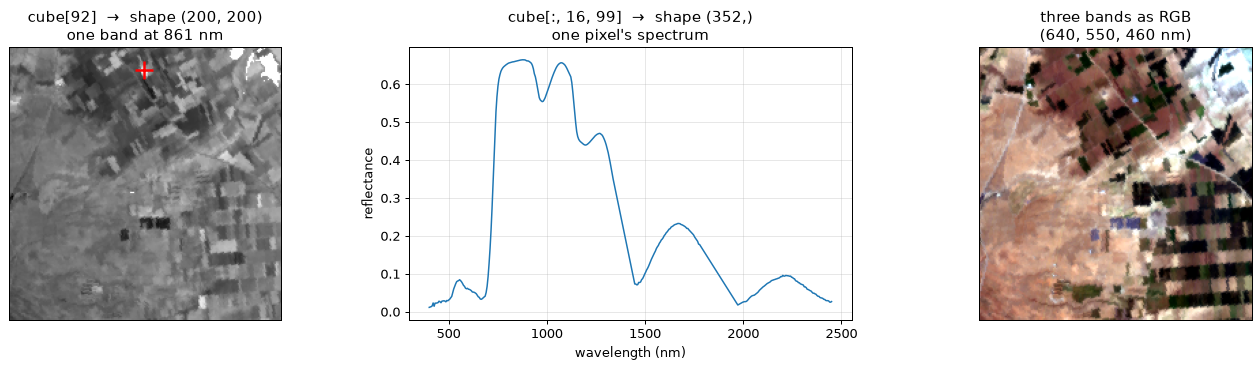

In [3]:
b_nir = hu.band_index(wl, 860)                 # position of the band nearest 860 nm
row, col = 16, 99                              # a green field pixel inside the window

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].imshow(cube[b_nir], cmap="gray")       # cube[b] → one band: a (rows, cols) image
axes[0].plot(col, row, "r+", ms=14, mew=2)
axes[0].set_title(f"cube[{b_nir}]  →  shape {cube[b_nir].shape}\none band at {wl[b_nir]:.0f} nm")

axes[1].plot(wl, cube[:, row, col], lw=1.2)    # cube[:, r, c] → one pixel: a (bands,) spectrum
axes[1].set(xlabel="wavelength (nm)", ylabel="reflectance",
            title=f"cube[:, {row}, {col}]  →  shape {cube[:, row, col].shape}\none pixel's spectrum")
axes[1].grid(alpha=0.3)

axes[2].imshow(hu.rgb_from_cube(cube, wl))     # three bands stacked → true colour
axes[2].set_title("three bands as RGB\n(640, 550, 460 nm)")
for ax in (axes[0], axes[2]):
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Indexing and slicing

The rules are the same as for any numpy array; the only new thing is that there are three axes, so you write three
slices separated by commas. `:` means "everything on this axis".

```
cube[b]            one band            (rows, cols)
cube[:, r, c]      one pixel           (bands,)
cube[:, r0:r1, c0:c1]   a block        (bands, r1-r0, c1-c0)
cube[::4]          every 4th band      (bands/4, rows, cols)
cube[-1]           the last band       (rows, cols)
```

In [4]:
examples = [
    ("cube[0]",                 cube[0]),
    ("cube[:, 10, 20]",         cube[:, 10, 20]),
    ("cube[:, 0:50, 0:50]",     cube[:, 0:50, 0:50]),
    ("cube[::4]",               cube[::4]),
    ("cube[:, ::2, ::2]",       cube[:, ::2, ::2]),
    ("cube[[b_nir, b_red]]",    cube[[b_nir, hu.band_index(wl, 665)]]),
]
for expr, arr in examples:
    print(f"{expr:24s} → shape {str(arr.shape):18s} {arr.nbytes / 1e6:6.1f} MB")

cube[0]                  → shape (200, 200)            0.2 MB
cube[:, 10, 20]          → shape (352,)                0.0 MB
cube[:, 0:50, 0:50]      → shape (352, 50, 50)         3.5 MB
cube[::4]                → shape (88, 200, 200)       14.1 MB
cube[:, ::2, ::2]        → shape (352, 100, 100)      14.1 MB
cube[[b_nir, b_red]]     → shape (2, 200, 200)         0.3 MB


### View or copy? It matters at this size

A **slice** is a *view*: a window onto the same memory, costing nothing. **Fancy indexing** (a list of indices, or a
boolean mask) makes a *copy*. With cubes of hundreds of megabytes the difference is not academic — and writing into
a view changes the original.

In [5]:
a_view = cube[0:10]                 # slice      → view
a_copy = cube[[0, 1, 2]]            # index list → copy

print(f"cube[0:10]    shares memory with cube: {np.shares_memory(cube, a_view)}")
print(f"cube[[0,1,2]] shares memory with cube: {np.shares_memory(cube, a_copy)}")

before = float(cube[0, 0, 0])
a_view[0, 0, 0] = -999              # writing into a view writes into the cube
print(f"\nafter writing into the view, cube[0,0,0] = {cube[0, 0, 0]} (was {before})")
cube[0, 0, 0] = before              # put it back
print("restored:", cube[0, 0, 0] == before)
print("\nIf you need to modify without side effects: arr = cube[0:10].copy()")

cube[0:10]    shares memory with cube: True
cube[[0,1,2]] shares memory with cube: False

after writing into the view, cube[0,0,0] = -999.0 (was 0.01674763858318329)
restored: True

If you need to modify without side effects: arr = cube[0:10].copy()


## 3. Reductions: the `axis` argument

`mean`, `median`, `std`, `sum`, `min`, `max` all take `axis`. **The axis you name is the one that disappears.**
That single sentence resolves most confusion.

| Call | Averages over | Result shape | What it is |
|---|---|---|---|
| `np.nanmean(cube, axis=0)` | all **bands** | `(rows, cols)` | a brightness image |
| `np.nanmean(cube, axis=(1, 2))` | all **pixels** | `(bands,)` | the scene's mean spectrum |
| `np.nanmean(cube, axis=1)` | rows | `(bands, cols)` | rarely useful — a vertical "slice" |
| `np.nanmean(cube)` | everything | scalar | one number |

> Why `np.nanmean` and not `.mean()`? 329 pixels in this window are cloud-flagged, and the course marks
> those `NaN`. A plain `.mean()` over the pixel axes would return `NaN` for **every band** — a blank plot.
> Section 6 explains the rule; for now note that the `axis` argument behaves identically either way.

np.nanmean(cube, axis=0)        → shape (200, 200)     (the named axis is gone)
np.nanmean(cube, axis=(1, 2))   → shape (352,)         (the named axis is gone)
np.nanmean(cube, axis=1)        → shape (352, 200)     (the named axis is gone)
np.nanmean(cube)                → shape ()             (the named axis is gone)


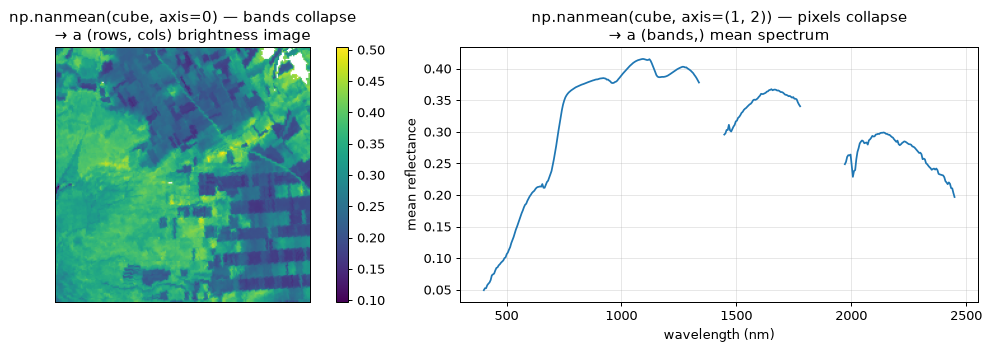

In [6]:
# 329 pixels in this window are fully masked, so nanmean warns "Mean of empty slice" about them.
# Section 6 explains what that means; silence it here so the shapes stay readable.
warnings.filterwarnings("ignore", message="Mean of empty slice")

for call, arr in [("np.nanmean(cube, axis=0)",      np.nanmean(cube, axis=0)),
                  ("np.nanmean(cube, axis=(1, 2))", np.nanmean(cube, axis=(1, 2))),
                  ("np.nanmean(cube, axis=1)",      np.nanmean(cube, axis=1)),
                  ("np.nanmean(cube)",              np.array(np.nanmean(cube)))]:
    print(f"{call:31s} → shape {str(arr.shape):14s} (the named axis is gone)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(np.nanmean(cube, axis=0), cmap="viridis")
axes[0].set_title("np.nanmean(cube, axis=0) — bands collapse\n→ a (rows, cols) brightness image")
axes[0].set_xticks([]); axes[0].set_yticks([])
plt.colorbar(im, ax=axes[0], fraction=0.046)

hu.plot_spectrum(axes[1], wl, np.nanmean(cube, axis=(1, 2)), lw=1.4)
axes[1].set(xlabel="wavelength (nm)", ylabel="mean reflectance",
            title="np.nanmean(cube, axis=(1, 2)) — pixels collapse\n→ a (bands,) mean spectrum")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### `keepdims=True`: the one that saves you later

A reduction removes the axis. `keepdims=True` keeps it with length 1 instead. That matters the moment you want to
*subtract* the result from the cube it came from, because numpy aligns shapes from the **right**.

```
cube                              (352, 200, 200)
np.nanmean(cube, axis=(1,2))      (352,)           ✗ cannot align: 352 against 200
np.nanmean(cube, axis=(1,2), keepdims=True)
                                  (352,   1,   1)  ✓ the 1s stretch to 200
```

In [7]:
mean_spectrum = np.nanmean(cube, axis=(1, 2))
mean_keep = np.nanmean(cube, axis=(1, 2), keepdims=True)
print(f"without keepdims: {mean_spectrum.shape}")
print(f"with keepdims:    {mean_keep.shape}")

try:
    centred = cube - mean_spectrum                      # the classic mistake
except ValueError as err:
    print("\ncube - mean(axis=(1,2)) raises:")
    print(" ", err)
    print("\nRead it right to left: numpy lines the shapes up from the last axis.")
    print("  cube is (352, 200, 200), the mean is (352,) which it treats as (1, 1, 352).")
    print("  200 vs 352 on the last axis → no way to stretch either to match.")

centred = cube - mean_keep                              # the fix
print(f"\ncube - mean(..., keepdims=True) → {centred.shape}, mean now ~0: "
      f"{float(np.nanmean(centred)):.2e}")

without keepdims: (352,)
with keepdims:    (352, 1, 1)

cube - mean(axis=(1,2)) raises:
  operands could not be broadcast together with shapes (352,200,200) (352,) 

Read it right to left: numpy lines the shapes up from the last axis.
  cube is (352, 200, 200), the mean is (352,) which it treats as (1, 1, 352).
  200 vs 352 on the last axis → no way to stretch either to match.

cube - mean(..., keepdims=True) → (352, 200, 200), mean now ~0: -1.87e-10


## 4. Broadcasting

Broadcasting is numpy stretching a small array over a big one without copying it. The rule: compare shapes from the
right; axes must be **equal**, or one of them must be **1**.

```
(352, 200, 200)  cube              (352, 200, 200)  cube
(352,   1,   1)  per-band value    (      200, 200)  per-pixel value
---------------                    ---------------
(352, 200, 200)  ✓ one number      (352, 200, 200)  ✓ one image applied
                 per band                            to every band
```

Both forms appear constantly: *per-band* for calibration and normalisation, *per-pixel* for masks and weights.

cube / (352, 1, 1)   → (352, 200, 200)   per-band normalisation
cube / (200, 200)    → (352, 200, 200)   per-pixel normalisation


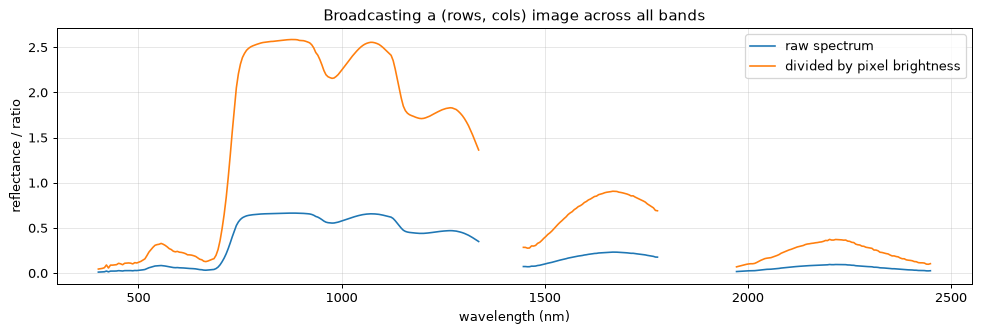

In [8]:
# per-band: continuum-style normalisation, each band divided by its own scene mean
per_band = cube / np.nanmean(cube, axis=(1, 2), keepdims=True)
print(f"cube / (352, 1, 1)   → {per_band.shape}   per-band normalisation")

# per-pixel: divide every band by that pixel's brightness (a crude illumination correction)
brightness = np.nanmean(cube, axis=0)               # (rows, cols)
per_pixel = cube / brightness                       # (352, 200, 200) / (200, 200) ✓
print(f"cube / (200, 200)    → {per_pixel.shape}   per-pixel normalisation")

row, col = 16, 99
fig, ax = plt.subplots(figsize=(11, 3.8))
hu.plot_spectrum(ax, wl, cube[:, row, col], lw=1.3, label="raw spectrum")
hu.plot_spectrum(ax, wl, per_pixel[:, row, col], lw=1.3, label="divided by pixel brightness")
ax.set(xlabel="wavelength (nm)", ylabel="reflectance / ratio",
       title="Broadcasting a (rows, cols) image across all bands")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Boolean masks

A mask is an array of `True`/`False` the same shape as what you are selecting. This is how the course keeps clouds,
no-data and non-target pixels out of every statistic — the equivalent of your "valid pixel" or "cloud mask" raster.

The idiom to memorise is **`cube[:, mask]`**: keep all bands, take only the pixels where the 2-D mask is `True`.
It returns a `(bands, n_selected)` matrix — the spatial layout is gone, which is exactly what you want before
computing statistics or feeding a classifier.

In [9]:
valid = scene.valid_mask(WINDOW)                 # no-data, cloud and cirrus all excluded
print(f"valid.shape = {valid.shape}, dtype = {valid.dtype}")
print(f"valid pixels: {valid.sum():,} of {valid.size:,} ({valid.mean() * 100:.1f}%)   "
      f"# True counts as 1, so .sum() counts and .mean() gives the fraction")

selected = cube[:, valid]
print(f"\ncube[:, valid] → {selected.shape}   (bands, selected pixels)")

# masks combine with & (and), | (or), ~ (not) — note the brackets, they are required
ndvi = hu.nd(cube[hu.band_index(wl, 860)], cube[hu.band_index(wl, 665)])
green = valid & (ndvi > 0.6)
bare = valid & (ndvi < 0.2)
print(f"\ngreen crops (NDVI > 0.6): {green.sum():,} px")
print(f"bare soil   (NDVI < 0.2): {bare.sum():,} px")
print(f"neither, or invalid:      {(~(green | bare)).sum():,} px")

valid.shape = (200, 200), dtype = bool
valid pixels: 39,671 of 40,000 (99.2%)   # True counts as 1, so .sum() counts and .mean() gives the fraction

cube[:, valid] → (352, 39671)   (bands, selected pixels)

green crops (NDVI > 0.6): 4,920 px
bare soil   (NDVI < 0.2): 18,945 px
neither, or invalid:      16,135 px


`np.where` has two jobs, and both appear in the course:

- `np.where(condition, a, b)` — element-wise choice, "a where the condition holds, else b".
- `np.where(condition)` — the *positions* where it holds, as index arrays.

np.where(valid, ndvi, np.nan) → (200, 200), 329 NaN pixels
np.where(green) → 4,920 positions, first: row 0, col 143


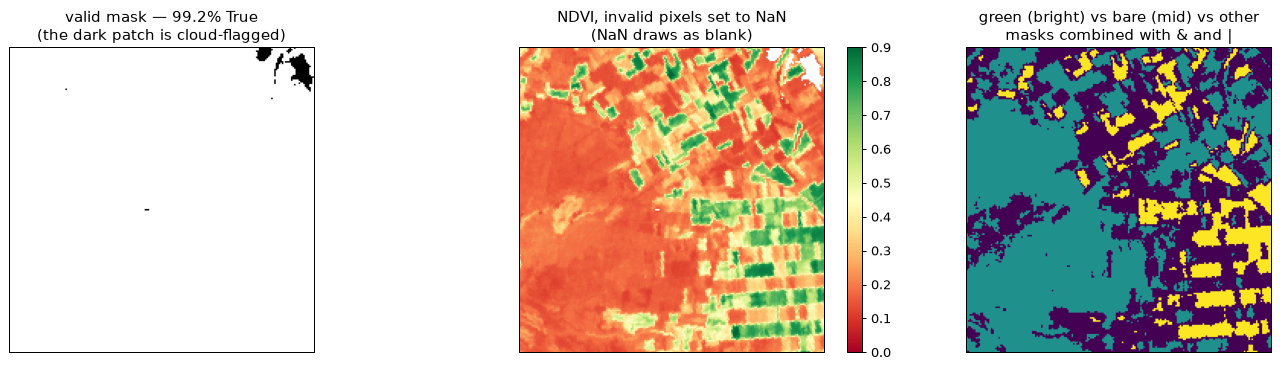

In [10]:
masked_ndvi = np.where(valid, ndvi, np.nan)      # keep NDVI where valid, NaN elsewhere
rows_idx, cols_idx = np.where(green)             # positions of the green pixels
print(f"np.where(valid, ndvi, np.nan) → {masked_ndvi.shape}, "
      f"{np.isnan(masked_ndvi).sum():,} NaN pixels")
print(f"np.where(green) → {len(rows_idx):,} positions, first: row {rows_idx[0]}, col {cols_idx[0]}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].imshow(valid, cmap="gray")
axes[0].set_title(f"valid mask — {valid.mean() * 100:.1f}% True\n(the dark patch is cloud-flagged)")
im = axes[1].imshow(masked_ndvi, cmap="RdYlGn", vmin=0, vmax=0.9)
axes[1].set_title("NDVI, invalid pixels set to NaN\n(NaN draws as blank)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].imshow(np.where(green, 1.0, np.where(bare, 0.5, 0.0)), cmap="viridis")
axes[2].set_title("green (bright) vs bare (mid) vs other\nmasks combined with & and |")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 6. NaN-safe maths

The course marks every invalid pixel as `NaN` rather than 0 or −9999. The reason is that `NaN` is *contagious*:
any arithmetic touching it returns `NaN`, so a masked pixel can never quietly pollute a result. The price is that
you must use the `nan*` versions of the reductions.

| Instead of | Use | Because |
|---|---|---|
| `mean` | `np.nanmean` | one NaN makes the plain mean NaN |
| `median`, `std`, `min`, `max` | `np.nanmedian`, `np.nanstd`, `np.nanmin`, `np.nanmax` | same |
| `argmax` | `np.nanargmax` | plain version returns the NaN's position |
| `x > 0` | `np.isfinite(x) & (x > 0)` | comparisons with NaN are always `False`, which hides pixels |

In [11]:
band = cube[b_nir]
print(f"NaN pixels in this band: {np.isnan(band).sum():,}")
print(f"band.mean()      = {band.mean():.4f}      ← one NaN poisons the whole result")
print(f"np.nanmean(band) = {np.nanmean(band):.4f}   ← what you wanted")

print("\nCounting NaNs and finite values:")
print(f"  np.isnan(band).sum()    = {np.isnan(band).sum():,}")
print(f"  np.isfinite(band).sum() = {np.isfinite(band).sum():,}")

print("\nThe 'All-NaN slice encountered' warning means a whole row/column/pixel was NaN:")
empty = np.full(10, np.nan)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    value = np.nanmean(empty)
    print(f"  np.nanmean(all-NaN) = {value} and warns: {caught[0].category.__name__}: {caught[0].message}")
print("  It is a warning, not an error — but check that the area you averaged is not entirely masked.")

NaN pixels in this band: 329
band.mean()      = nan      ← one NaN poisons the whole result
np.nanmean(band) = 0.3794   ← what you wanted

Counting NaNs and finite values:
  np.isnan(band).sum()    = 329
  np.isfinite(band).sum() = 39,671

The 'All-NaN slice encountered' warning means a whole row/column/pixel was NaN:
  np.nanmean(all-NaN) = nan and warns: RuntimeWarning: Mean of empty slice
  It is a warning, not an error — but check that the area you averaged is not entirely masked.


## 7. Cube ↔ pixel matrix

Every classifier in scikit-learn (and every one in notebooks 15 and 20) wants a 2-D matrix shaped
**`(n_samples, n_features)`** — here, `(pixels, bands)`. Converting is two reshapes and a transpose. Do it by hand
once; after that use the helpers.

In [12]:
b, h, w = cube.shape

flat = cube.reshape(b, -1)          # (bands, rows*cols)  — -1 means "work it out"
X_all = flat.T                      # (rows*cols, bands)  — .T swaps the two axes
ok = np.all(np.isfinite(X_all), axis=1)     # rows with no NaN: a per-pixel mask
X = X_all[ok]                               # (complete pixels, bands)

print(f"cube            {cube.shape}")
print(f"  .reshape(b,-1){flat.shape}")
print(f"  .T            {X_all.shape}")
print(f"  [ok]          {X.shape}   ← ready for sklearn: {X.shape[0]:,} samples, {X.shape[1]} features")

X_hu, mask_hu = hu.cube_to_pixels(cube)     # the course helper does exactly this
print(f"\nhu.cube_to_pixels(cube) → X {X_hu.shape}, mask {mask_hu.shape}")
print("identical to the manual version:", np.array_equal(X, X_hu))

cube            (352, 200, 200)
  .reshape(b,-1)(352, 40000)
  .T            (40000, 352)
  [ok]          (39671, 352)   ← ready for sklearn: 39,671 samples, 352 features

hu.cube_to_pixels(cube) → X (39671, 352), mask (200, 200)
identical to the manual version: True


Going back is the part people forget: a per-pixel result (a class label, a cluster number, a probability) is a
**1-D array in the order of the selected pixels**. `pixels_to_image` scatters it back onto the grid so you can map it.

X (39671, 352) → distance (39671,)  (one number per pixel)
hu.pixels_to_image(...) → (200, 200)


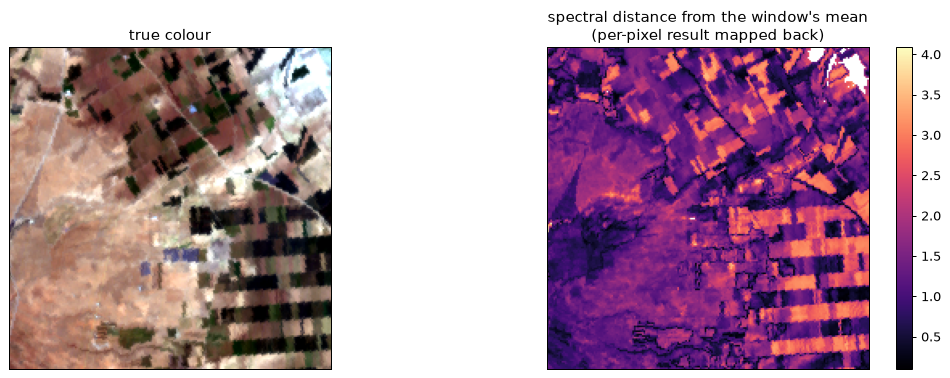

In [13]:
# a per-pixel number: distance from the mean spectrum, which highlights unusual pixels
distance = np.linalg.norm(X - X.mean(axis=0), axis=1)      # (n_pixels,) — axis=1 collapses the bands
print(f"X {X.shape} → distance {distance.shape}  (one number per pixel)")

image = hu.pixels_to_image(distance, mask_hu)              # back to (rows, cols), NaN where masked
print(f"hu.pixels_to_image(...) → {image.shape}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].imshow(hu.rgb_from_cube(cube, wl)); ax[0].set_title("true colour")
im = ax[1].imshow(image, cmap="magma")
ax[1].set_title("spectral distance from the window's mean\n(per-pixel result mapped back)")
plt.colorbar(im, ax=ax[1], fraction=0.046)
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 8. Reading the course code

Two real lines from the course, taken apart. If you can follow these, the rest of the notebooks will read easily.

### 8.1 The noise estimate in notebook 11

```python
mad = np.nanmedian(np.abs(d - np.nanmedian(d, axis=(1, 2), keepdims=True)), axis=(1, 2))
```

Working from the inside out, where `d` is the difference between neighbouring columns, shaped `(bands, rows, cols-1)`:

| Step | Expression | Shape | What it does |
|---|---|---|---|
| 1 | `np.nanmedian(d, axis=(1, 2), keepdims=True)` | `(352, 1, 1)` | the typical difference **per band** — `keepdims` so step 2 can broadcast |
| 2 | `d - …` | `(352, 200, 199)` | centre each band on its own median |
| 3 | `np.abs(…)` | `(352, 200, 199)` | absolute deviations |
| 4 | `np.nanmedian(…, axis=(1, 2))` | `(352,)` | the median absolute deviation **per band** |

The result is one robust noise number per band — a spectrum of noise, which is what the figure in notebook 11 plots.

d                          (352, 200, 199)   
1. nanmedian(keepdims)     (352, 1, 1)       
2. d - median              (352, 200, 199)   
3. abs(...)                (352, 200, 199)   
4. nanmedian(axis=(1,2))   (352,)            


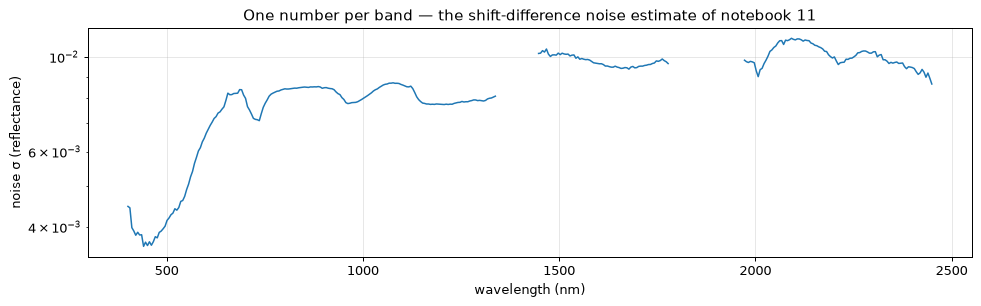

In [14]:
d = cube[:, :, 1:] - cube[:, :, :-1]            # neighbouring-column differences
step1 = np.nanmedian(d, axis=(1, 2), keepdims=True)
step2 = d - step1
step3 = np.abs(step2)
step4 = np.nanmedian(step3, axis=(1, 2))
noise = 1.4826 * step4 / np.sqrt(2)              # MAD → σ for Gaussian noise, ÷√2 for the differencing

for name, arr in [("d", d), ("1. nanmedian(keepdims)", step1), ("2. d - median", step2),
                  ("3. abs(...)", step3), ("4. nanmedian(axis=(1,2))", step4)]:
    print(f"{name:26s} {str(arr.shape):18s}")

fig, ax = plt.subplots(figsize=(11, 3.5))
hu.plot_spectrum(ax, wl, noise, lw=1.2)
ax.set(xlabel="wavelength (nm)", ylabel="noise σ (reflectance)", yscale="log",
       title="One number per band — the shift-difference noise estimate of notebook 11")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 8.2 Band depth, from `hsi_utils`

```python
t = (wl[iC] - wl[iL]) / (wl[iR] - wl[iL])
cont = rL + t * (rR - rL)
return 1.0 - rC / (cont + 1e-12)
```

This measures how deep an absorption feature is. `iL`, `iC`, `iR` are the band positions of the left shoulder, the
feature centre and the right shoulder. `t` is how far the centre sits between the shoulders (0 → at the left, 1 → at
the right), so `cont` is the straight line between the shoulders evaluated at the centre — the reflectance you
*would* see without the absorption. The depth is the fractional drop below that line. The `+ 1e-12` prevents a
division by zero on black pixels.

The quiet trick: `rL`, `rC`, `rR` can each be a single number **or** a whole `(rows, cols)` image. The arithmetic is
identical, so the same three lines give you one depth value for a library spectrum or a depth *map* for a cube —
this is what "vectorised" buys you.

band_depth(cube)     → (200, 200)  (a map)
band_depth(spectrum) → ()        (one number: 0.906)
Same function, same three lines of arithmetic — only the input shape changed.


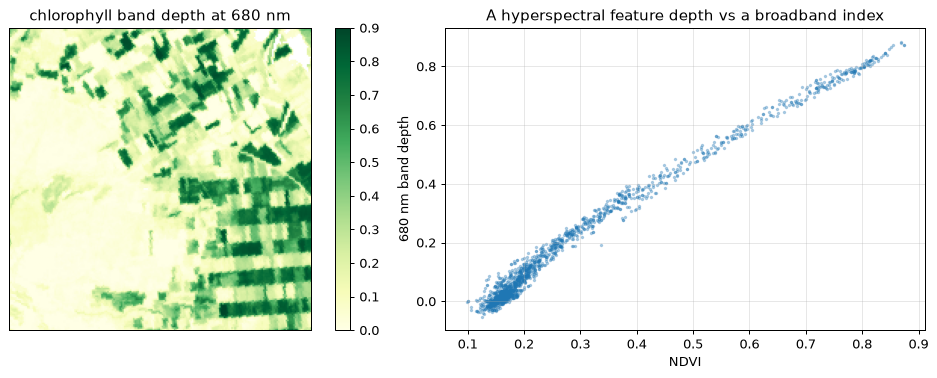

In [15]:
# the chlorophyll feature at 680 nm, with shoulders at 550 and 750 nm
depth_map = hu.band_depth(wl, cube, 550, 680, 750)             # cube in → (rows, cols) map out
spectrum = cube[:, 16, 99]
depth_one = hu.band_depth(wl, spectrum, 550, 680, 750)         # spectrum in → one number out

print(f"band_depth(cube)     → {depth_map.shape}  (a map)")
print(f"band_depth(spectrum) → {np.shape(depth_one)}        (one number: {depth_one:.3f})")
print("Same function, same three lines of arithmetic — only the input shape changed.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
im = ax[0].imshow(np.where(valid, depth_map, np.nan), cmap="YlGn", vmin=0, vmax=0.9)
ax[0].set_title("chlorophyll band depth at 680 nm"); ax[0].set_xticks([]); ax[0].set_yticks([])
plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].scatter(ndvi[valid][::25], depth_map[valid][::25], s=3, alpha=0.3)
ax[1].set(xlabel="NDVI", ylabel="680 nm band depth",
          title="A hyperspectral feature depth vs a broadband index")
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Why vectorise?

The habit worth forming: express an operation over *all* pixels at once and let numpy run the loop in C. The
difference is not stylistic.

In [16]:
import time

red, nir = cube[hu.band_index(wl, 665)], cube[hu.band_index(wl, 860)]

t0 = time.perf_counter()
out_loop = np.empty_like(red)
for r in range(red.shape[0]):
    for c in range(red.shape[1]):
        out_loop[r, c] = (nir[r, c] - red[r, c]) / (nir[r, c] + red[r, c] + 1e-6)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
out_vec = (nir - red) / (nir + red + 1e-6)
t_vec = time.perf_counter() - t0

print(f"python loop over {red.size:,} pixels : {t_loop * 1000:7.1f} ms")
print(f"vectorised                        : {t_vec * 1000:7.1f} ms")
print(f"speed-up                          : {t_loop / t_vec:7.0f}×")
print(f"identical results: {np.allclose(out_loop, out_vec, equal_nan=True)}")
scale = scene.shape[1] * scene.shape[2] / red.size * len(wl)     # whole scene, every band
print(f"\nScaled to the full scene ({scene.shape[1] * scene.shape[2]:,} px) and all {len(wl)} bands:")
print(f"  loop       : {t_loop * scale:6.1f} s")
print(f"  vectorised : {t_vec * scale:6.1f} s")

python loop over 40,000 pixels :    11.2 ms
vectorised                        :     0.2 ms
speed-up                          :      45×
identical results: True

Scaled to the full scene (522,248 px) and all 352 bands:
  loop       :   51.7 s
  vectorised :    1.1 s


## ✏️ Your turn

**1. Slice the cube.** Print the shape of: (a) the first 10 bands over the whole window, (b) the spectrum of the
pixel at row 50, column 166, (c) a 20 × 20 block at the window's top-left corner, all bands.
<details><summary>Hint</summary>

One slice per axis, separated by commas: `cube[a:b, c:d, e:f]`. Leave an axis as `:` to keep all of it.
</details>
<details><summary>Solution</summary>

```python
print(cube[:10].shape)            # (10, 200, 200)
print(cube[:, 50, 166].shape)     # (352,)
print(cube[:, :20, :20].shape)    # (352, 20, 20)
```
</details>

**2. Mean spectra of two classes.** Using the `green` and `bare` masks from section 5, compute the mean spectrum of
each and plot them on one axis. Which wavelength shows the biggest difference?
<details><summary>Hint</summary>

`cube[:, green]` gives `(bands, n_pixels)`; average over axis 1. Then `np.nanargmax(np.abs(a - b))` and look up `wl`.
</details>
<details><summary>Solution</summary>

```python
mean_green = np.nanmean(cube[:, green], axis=1)
mean_bare = np.nanmean(cube[:, bare], axis=1)
fig, ax = plt.subplots(figsize=(11, 4))
hu.plot_spectrum(ax, wl, mean_green, label="green crops")
hu.plot_spectrum(ax, wl, mean_bare, label="bare soil")
ax.legend(); ax.grid(alpha=0.3); plt.show()

i = np.nanargmax(np.abs(mean_green - mean_bare))
print(f"largest difference at {wl[i]:.0f} nm")      # the NIR plateau, around 800–900 nm
```
</details>

**3. Normalise each spectrum to unit brightness.** Divide every pixel's spectrum by its own mean so that only
*shape* remains (this is what makes the Spectral Angle Mapper brightness-invariant, notebook 10). Check that the
mean of each normalised spectrum is 1.
<details><summary>Hint</summary>

You need the per-pixel mean with the band axis kept: `np.nanmean(cube, axis=0, keepdims=True)` → `(1, rows, cols)`.
</details>
<details><summary>Solution</summary>

```python
shape_only = cube / np.nanmean(cube, axis=0, keepdims=True)
print(shape_only.shape, float(np.nanmean(shape_only[:, 16, 99])))   # ≈ 1.0
```
</details>

**4. Count without a loop.** How many valid pixels have NDVI above 0.6 *and* a 680 nm band depth above 0.5? Express
it as a percentage of valid pixels.
<details><summary>Hint</summary>

Combine masks with `&`, then `.sum()`. Remember `valid` to exclude cloud.
</details>
<details><summary>Solution</summary>

```python
both = valid & (ndvi > 0.6) & (depth_map > 0.5)
print(f"{both.sum():,} px ({both.sum() / valid.sum() * 100:.1f}% of valid)")
```
</details>

**5. Round trip.** Take `X, mask = hu.cube_to_pixels(cube)`, compute each pixel's maximum reflectance
(`X.max(axis=1)`), map it back with `hu.pixels_to_image`, and display it. Why is `axis=1` the right axis here?
<details><summary>Hint</summary>

`X` is `(pixels, bands)`. Collapsing axis 1 leaves one number per pixel.
</details>
<details><summary>Solution</summary>

```python
X, mask = hu.cube_to_pixels(cube)
brightest = X.max(axis=1)                    # (pixels,) — the band axis disappears
plt.imshow(hu.pixels_to_image(brightest, mask), cmap="magma"); plt.colorbar(); plt.show()
```
</details>

## Cheat sheet

The ten operations the rest of the course is built from.

| # | Operation | Idiom | Result |
|---|---|---|---|
| 1 | read a window | `cube, wl = scene.read_cube((r0, r1, c0, c1))` | `(bands, rows, cols)`, nm |
| 2 | one band | `cube[b]` or `cube[hu.band_index(wl, 860)]` | `(rows, cols)` |
| 3 | one spectrum | `cube[:, r, c]` | `(bands,)` |
| 4 | mean spectrum | `np.nanmean(cube, axis=(1, 2))` | `(bands,)` |
| 5 | brightness image | `np.nanmean(cube, axis=0)` | `(rows, cols)` |
| 6 | per-band maths | `cube - np.nanmean(cube, axis=(1, 2), keepdims=True)` | `(bands, rows, cols)` |
| 7 | valid mask | `valid = scene.valid_mask(window)`; `valid.sum()` | `(rows, cols)` bool |
| 8 | select pixels | `cube[:, valid]` | `(bands, n_valid)` |
| 9 | matrix for sklearn | `X, mask = hu.cube_to_pixels(cube)` | `(pixels, bands)` |
| 10 | result back on the map | `hu.pixels_to_image(values, mask)` | `(rows, cols)` |

**Three rules worth memorising**

1. The axis you name in a reduction is the one that **disappears**.
2. `keepdims=True` whenever the result will be combined with the array it came from.
3. Invalid pixels are `NaN`, so reach for `np.nanmean`, `np.nanmedian`, `np.isfinite` — not `mean`, `median`, `> 0`.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC